In [1]:
import numpy as np
import matplotlib.pyplot as plt
def RMSD_func(t,bt0,bt1,return_a = False):
    P = bt0
    Q = bt1
    a = np.trapezoid(P * Q,t) / np.trapezoid(Q**2,t)
    if return_a:
        return np.sqrt(np.trapezoid((P-a*Q)**2,t)/np.trapezoid(P**2,t)),a
    else:
        return np.sqrt(np.trapezoid((P-a*Q)**2,t)/np.trapezoid(P**2,t))

# Load and complete the hydarulic and btc data

In [2]:
import pandas as pd
import numpy as np
from scipy.interpolate import Akima1DInterpolator
import matplotlib.pyplot as plt
import csv
def data(file_path):
    """
    Parses and processes breakthrough curve (BTC) data from a CSV file.

    The function extracts time series and concentration data for multiple BTCs
    from a structured CSV file. It filters BTCs based on specific metadata conditions
    and optionally extends each BTC with zero-padding before and after the observed data
    to ensure consistent temporal coverage.

    Parameters:
        file_path (str): Path to the CSV file containing BTC data in a tabular format.
        complete_zeros (bool): If True, extends the BTCs with zero values before and after
                               the observation period using interpolation. If False, returns
                               the trimmed, background-corrected data.

    Returns:
        n_btcs (int): Number of valid BTCs processed.
        ts_m (list of np.ndarray): Time arrays for each BTC (possibly extended).
        btcs_m (list of np.ndarray): Concentration arrays for each BTC, background-corrected.
        xs_m (list of float): Streamwise positions (or equivalent spatial data) for each BTC.
        names_list (list of str): List of BTC identifiers or names from the data.
    """

    with open(file_path, 'r') as file:
        data_reader = csv.reader(file)
        data_mat =  [[cell for cell in row] for row in data_reader]
        max_len = max(len(row) for row in data_mat)
        padded_data = [row + [''] * (max_len - len(row)) for row in data_mat]
        breakthrough_curves_data = [[[padded_data[i][i_btc*5+j] for i in range(len(padded_data))] for j in range(4)] for i_btc in range(len(padded_data[0])//5)]

    #Change time units from hours to seconds and length units from kilometers to meters
    ts_m = [np.array([float(c)*3600 for c in btc[0][33:] if c!='']) for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    btcs_m = [np.array([float(c) for c in btc[3][33:] if c!='']) for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    xs_m = [btc[2][18] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    xs_m = [float(i)*1000 if i!='' else 0.0 for i in xs_m]
    params_m = [btc[2][2:5]+btc[2][9:13]+[btc[2][18]] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    background_cs_m = [btc[2][25] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    background_cs_m = [float(i) if i!='' else 0.0 for i in background_cs_m]
    names_list = [btc[0][31] for btc in breakthrough_curves_data if len([float(c) for c in btc[3][33:] if c!=''])>0 and btc[2][18] not in ['','0'] and btc[2][26] in ['','0','0.0']]
    n_btcs = len(ts_m)

    for i_btc in range(n_btcs):
        if len(ts_m[i_btc])<len(btcs_m[i_btc]):
            btcs_m[i_btc] = btcs_m[i_btc][:len(ts_m[i_btc])]
        if len(ts_m[i_btc])>len(btcs_m[i_btc]):
            ts_m[i_btc] = ts_m[i_btc][:len(btcs_m[i_btc])]
        sorted_indices = np.argsort(ts_m[i_btc])
        ts_m[i_btc] = ts_m[i_btc][sorted_indices]
        btcs_m[i_btc] = btcs_m[i_btc][sorted_indices]
        _,unique_idices = np.unique(ts_m[i_btc],return_index=True)
        ts_m[i_btc] = ts_m[i_btc][unique_idices]
        btcs_m[i_btc] = btcs_m[i_btc][unique_idices]
        btcs_m[i_btc] = np.maximum(btcs_m[i_btc],np.zeros_like(btcs_m[i_btc]))
        if btcs_m[i_btc][0]>0.0 and 0.0 in btcs_m[i_btc] and np.sum(btcs_m[i_btc][np.where(btcs_m[i_btc]==0)[0][0]:])>0.0:
            btcs_m[i_btc][:np.where(btcs_m[i_btc]==0)[0][0]]=0.0

    m1s = np.array([np.trapezoid(btc*t,x=t)/np.trapezoid(btc,x=t) for t,btc in zip(ts_m,btcs_m)])
    m2s = np.array([np.trapezoid(btc*(t-m1)**2,x=t)/np.trapezoid(btc,x=t) for t,btc,m1 in zip(ts_m,btcs_m,m1s)])
    m3s = np.array([np.trapezoid(btc*(t-m1)**3,x=t)/np.trapezoid(btc,x=t) for t,btc,m1 in zip(ts_m,btcs_m,m1s)])
    m4s = np.array([np.trapezoid(btc*(t-m1)**4,x=t)/np.trapezoid(btc,x=t) for t,btc,m1 in zip(ts_m,btcs_m,m1s)])

    m0s = np.array([np.trapezoid(btc,x=t) for t,btc in zip(ts_m,btcs_m)])
    xs_m = np.array(xs_m)
    names_list = np.array(names_list)
    return n_btcs, ts_m, btcs_m, xs_m, names_list, m0s, m1s, m2s, m3s, m4s

In [3]:
n_btcs, ts_m, btcs_m, xs_m, names_list, m0s, m1s, m2s, m3s, m4s = data('river_solute_tracer_data.csv') # As downloaded from TIERRAS
df_params = pd.read_csv('estimated_parameters_breakthrough_curves_with_hydraulic_data.csv', index_col=29)
moms_cols = ['m'+str(i) for i in range(5)]
df_moments = pd.DataFrame(np.stack([m0s, m1s, m2s, m3s, m4s]).T,columns = moms_cols,index = names_list)
df_all = pd.concat([df_params,df_moments],axis = 1)
df_all['Stream Slope'] = df_all['Stream Slope']/1000
df_all["Sampling Location"] = df_all["Sampling Location"]*1000
model_params_cols_orig = ["('first order, semi-infinite-conc', 'v')","('', 'D')","('', 'beta*k_f')","('', 'k_r')"]
model_params_cols = [r'$v$',r'$D$',r'$\beta k_f$',r'$k_r$']
df_all = df_all.rename(columns={m:n for m,n in zip(model_params_cols_orig,model_params_cols)})
hydraulic_params_cols = ['Discharge','Velocity','Shear Velocity','Stream Slope','Stream Width','Channel Depth','Channel Cross Sectional Area']
df_all['v'] = df_all[r'$v$']/3.6
df_all['D'] = df_all[r'$D$']/0.0036
df_all['k'] = df_all[r'$k_r$']/3600
df_all['Pe'] = df_all['v']*df_all["Sampling Location"]/df_all[r'$D$']
df_all['beta'] = df_all[r'$\beta k_f$']/df_all[r'$k_r$']
df_all['kr_hat'] = df_all[r'$k_r$']*df_all["Sampling Location"]/df_all["v"]
df_all['t_peak'] = np.array([ts_m[list(names_list).index(df_all.index[i_])][np.argmax(btcs_m[list(names_list).index(df_all.index[i_])])] for i_ in range(len(df_all))])
df_all['v_peak'] = df_all["Sampling Location"]/df_all['t_peak']/3.6
neg_m3_idx = np.where(df_all['m3']<0)[0]
ts_m = [ts_m[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)]
btcs_m = [btcs_m[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)]
xs_m = np.array([xs_m[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
names_list = np.array([names_list[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
m0s = np.array([m0s[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
m1s = np.array([m1s[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
m2s = np.array([m2s[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
m3s = np.array([m3s[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
m4s = np.array([m4s[list(names_list).index(df_all.index[i_])] for i_ in range(len(df_all)) if not(i_ in neg_m3_idx)])
df_all = df_all.drop(df_all.index[neg_m3_idx])
df_all = df_all.reindex()
n_btcs = len(ts_m)
tracer_test = np.array([' '.join(n.split(' ')[:2])+((not n.split(' ')[2][1].isdigit())*(' '+n.split(' ')[2][1])) for n in df_all.index])
df_all['Tracer Name'] = tracer_test

groups = df_all.groupby(['Tracer Name', 'Sampling Location']).indices

# Build dict of first and subsequent indices
result = {
    key: {'duplicates': [int(i) for i in vals] if len(vals) > 1 else []
    }
    for key, vals in groups.items() if len(vals) > 1
}

all_later_duplicates = []
for dup_group in result.keys():
  t_m_new = np.unique([item for i in result[dup_group]['duplicates'] for item in ts_m[i]])
  btc_m_new = np.zeros_like(t_m_new)
  for i in result[dup_group]['duplicates']:
    btc_m_new += np.interp(t_m_new,ts_m[i],btcs_m[i],left = 0.0, right = 0.0)/len(result[dup_group]['duplicates'])
  ts_m[result[dup_group]['duplicates'][0]] = t_m_new
  btcs_m[result[dup_group]['duplicates'][0]] = btc_m_new
  all_later_duplicates.extend(result[dup_group]['duplicates'][1:])
  m0 = np.trapezoid(btc_m_new,t_m_new)
  idx_loc = df_all.iloc[result[dup_group]['duplicates'][0]].name
  df_all.loc[idx_loc,'m0'] = m0
  m1 = np.trapezoid(btc_m_new*t_m_new,t_m_new)/m0
  df_all.loc[idx_loc,'m1'] = m1
  for i in range(2,5):
    df_all.loc[idx_loc,'m'+str(i)] = np.trapezoid(btc_m_new*(t_m_new-m1)**i,t_m_new)/m0
for i in range(1,5):
    df_all['st_m'+str(i)] = np.sign(df_all['m'+str(i)])*np.abs(df_all['m'+str(i)])**(1/i)/df_all['Sampling Location']
df_all['skw'] = df_all['m3']/df_all['m2']**(3/2)
df_all['kurt'] = df_all['m4']/df_all['m2']**(2)
df_all['exc_kurt'] = df_all['m4']/df_all['m2']**(2)-3

ts_m = [ts_m[i] for i in range(n_btcs) if not(i in all_later_duplicates)]
btcs_m = [btcs_m[i] for i in range(n_btcs) if not(i in all_later_duplicates)]
xs_m = np.array([xs_m[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
names_list = np.array([names_list[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
m0s = np.array([m0s[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
m1s = np.array([m1s[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
m2s = np.array([m2s[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
m3s = np.array([m3s[i] for i in range(n_btcs) if not(i in all_later_duplicates)])
m4s = np.array([m4s[i] for i in range(n_btcs) if not(i in all_later_duplicates)])

n_btcs = len(ts_m)

df_all = df_all.drop(df_all.index[all_later_duplicates])
groups = tracer_test = np.array([' '.join(n.split(' ')[:2])+((not n.split(' ')[2][1].isdigit())*(' '+n.split(' ')[2][1])) for n in df_all.index])

In [4]:

for hp in hydraulic_params_cols:
  df_all[hp+' Reach Mean'] = np.nan
for trac_name in np.unique(tracer_test):
  loc = (df_all['Tracer Name'] == trac_name)
  for hp in hydraulic_params_cols:
    if np.any(~df_all[hp][loc].isna()):
      x = df_all['Sampling Location'][loc].values
      var = df_all[hp][loc].values[np.argsort(x)]
      mask_not_nan = ~(df_all[hp][loc].isna().values)[np.argsort(x)]
      x = np.sort(x)
      loc_var = np.interp(np.concatenate(([0],x)),x[mask_not_nan],var[mask_not_nan])
      df_all.loc[loc,hp+' Reach Mean'] = (np.array([np.trapezoid(loc_var[:i+2],x = np.concatenate(([0],x))[:i+2])/x[i] for i in range(len(loc_var)-1)]))

hydraulic_params_cols_reach_mean = [hp+' Reach Mean' for hp in hydraulic_params_cols]

In [5]:
g = 9.81
nu = 10**-6
for i in range(3):
  df_all.loc[df_all['Channel Cross Sectional Area Reach Mean'].isna(),'Channel Cross Sectional Area Reach Mean'] = (df_all['Discharge Reach Mean']/df_all['Velocity Reach Mean'])
  df_all.loc[df_all['Channel Cross Sectional Area Reach Mean'].isna(),'Channel Cross Sectional Area Reach Mean'] = (df_all['Stream Width Reach Mean']*df_all['Channel Depth Reach Mean'])

  df_all.loc[df_all['Velocity Reach Mean'].isna(),'Velocity Reach Mean'] = (df_all['Discharge Reach Mean']/df_all['Channel Cross Sectional Area Reach Mean'])

  df_all.loc[df_all['Stream Width Reach Mean'].isna(),'Stream Width Reach Mean'] = (df_all['Channel Cross Sectional Area Reach Mean']/df_all['Channel Depth Reach Mean'])

  df_all.loc[df_all['Stream Width Reach Mean'].isna(),'Channel Depth Reach Mean'] = (df_all['Channel Cross Sectional Area Reach Mean']/df_all['Stream Width Reach Mean'])

  df_all.loc[df_all['Shear Velocity Reach Mean'].isna(),'Shear Velocity Reach Mean'] = (g*df_all['Channel Depth Reach Mean']*df_all['Stream Slope Reach Mean'])**(1/2)

  df_all.loc[df_all['Stream Slope Reach Mean'].isna(),'Stream Slope Reach Mean'] = df_all['Shear Velocity Reach Mean']**2/(g*df_all['Channel Depth Reach Mean'])

  df_all.loc[df_all['Channel Depth Reach Mean'].isna(),'Channel Depth Reach Mean'] = df_all['Shear Velocity Reach Mean']**2/(g*df_all['Stream Slope Reach Mean'])

In [6]:
df_all['U'] = df_all['Discharge Reach Mean']/(df_all['Channel Depth Reach Mean']*df_all['Stream Width Reach Mean'])
df_all['B'] = df_all['Stream Width Reach Mean']
df_all['H'] = df_all['Channel Depth Reach Mean']
df_all['S_0'] = df_all['Stream Slope Reach Mean']
df_all['u_star'] = np.sqrt(g*df_all['H']*df_all['S_0'])
df_all['L'] = df_all['Sampling Location']
df_all['m1_dimless'] = (df_all['m1']*df_all['U'])/(df_all['L'])
df_all['m2_dimless'] = (df_all['m2']*df_all['U']*df_all['u_star']*df_all['H'])/(df_all['L']*df_all['B']**2)
df_all['m3_dimless'] = (df_all['m3']*df_all['U']*df_all['u_star']**2*df_all['H']**2)/(df_all['L']*df_all['B']**4)
df_all['m4_dimless'] = (df_all['m4']*df_all['U']**2*df_all['u_star']**2*df_all['H']**2)/(df_all['L']**2*df_all['B']**4)
df_all['v_dimless'] = df_all['v']/df_all['U']
df_all['D_dimless'] =  (df_all['D']*df_all['u_star']*df_all['H'])/(df_all['U']**2*df_all['B']**2)
df_all['beta_dimless'] =  df_all['beta']
df_all['k_dimless'] =  (df_all[r'$k_r$']*df_all['H']**2)/(df_all['u_star']*df_all['H'])
df_all['Re'] = df_all['U']*df_all['H']/nu
df_all['Fr'] = df_all['U']/np.sqrt(df_all['H']*g)
df_all['alpha'] = df_all['u_star']/df_all['U']
df_all['eta'] = df_all['B']/df_all['H']
df_all['lambda'] = df_all['L']/df_all['B']
hydraulic_params_cols_reach_mean_dimless = ['Re','Fr','alpha', 'eta','lambda']

In [7]:
np.nanmedian(df_all['B']**2*df_all['U']/(0.6*df_all['H']*df_all['u_star']))

np.float64(20102.289484658002)

In [8]:
np.nanmedian(df_all['L'])

np.float64(18587.877)

In [9]:
np.nanpercentile((df_all['L'])/(df_all['B']**2*df_all['U']/(0.6*df_all['H']*df_all['u_star'])),[10,50,90])

array([ 0.1459432 ,  1.14332007, 15.66376098])

In [10]:
np.nanmedian(df_all['skw'])

np.float64(1.3336743689023127)

In [11]:
epsilon_t0 = 0.145+1/3520/df_all['alpha']*df_all['eta']*1.38
df_all['D_pred_Deng'] = 1/(8*epsilon_t0)*0.01/df_all['eta']**(1/3)
df_all['psi'] = df_all['m2_dimless']/(2*df_all['D_pred_Deng'] )
print('psi Deng,',np.exp(np.mean(np.log(df_all['psi']))))
df_all['psi_dimless'] = df_all['psi']
df_all['dim_m2_2D_ratio'] = df_all['m2_dimless']/(2*df_all['D_dimless'])
df_all['Deng_D_ratio'] = df_all['D_pred_Deng'] /df_all['D_dimless']

psi Deng, 10.466686582502872


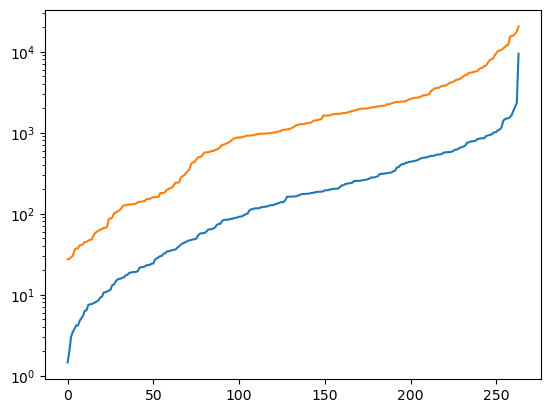

In [25]:
plt.semilogy(np.sort(2*df_all['m1']**2/df_all['m2']))
plt.semilogy(np.sort(df_all['v']*df_all['L']/df_all['D']))

In [26]:
np.percentile(2*df_all['m1']**2/df_all['m2'],[20,50,80]),np.percentile(df_all['v']*df_all['L']/df_all['D'],[20,50,80])

(array([ 28.48865488, 162.62381975, 503.38277067]),
 array([ 161.14878235, 1162.8555383 , 2962.63902019]))

# Learn moments directly or through parameters

In [31]:
import itertools
params_combinations = [[]]
params_combinations_label = [['None']]

# Loop from length 1 up to the total length of the list
for r in range(1, len(hydraulic_params_cols_reach_mean_dimless) + 1):
    params_combinations.extend([list(i) for i in itertools.combinations(hydraulic_params_cols_reach_mean_dimless, r)])
    params_combinations_label.extend([[fr'$\{j}$' if j!='Re' and j!='Fr' else fr'${j}$' for j in i] for i in itertools.combinations(hydraulic_params_cols_reach_mean_dimless, r)])
target_params_dimensional = ['m1','m2','m3','m4','v','D','beta','k','psi']
target_params = [i+'_dimless' for i in target_params_dimensional]


In [32]:
df_filt = df_all[['Tracer Name','L','skw','kurt','exc_kurt','dim_m2_2D_ratio','Deng_D_ratio']+target_params_dimensional+target_params+hydraulic_params_cols_reach_mean_dimless].copy()

# Complete cases
mask = ~df_filt.isna().any(axis=1)
df_filt = df_filt.loc[mask].copy()

# print(f"Number of BTCs: {len(df_filt)}")
# ============================================================
# GROUP LABELS
# ============================================================
# BTC
N = len(df_filt)
groups_btc = np.arange(N)[:,None]


# TRACER TEST
def get_trac(name):
    return ' '.join(name.split(' ')[:2])
df_filt['trac_test'] = df_filt['Tracer Name'].apply(get_trac)

trac_names,locs_trac= np.unique(df_filt['trac_test'].values,return_inverse = True)
groups_trac = [np.arange(N)[locs_trac==i] for i in range(len(trac_names))]

# RIVER
def get_river(name):
    return name.split(' ')[0]
tags_river = df_filt['Tracer Name'].apply(get_river).values
river_names,locs_river= np.unique(tags_river,return_inverse = True)
groups_river = [np.arange(N)[locs_river==i] for i in range(len(river_names))]


In [33]:
%%time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
r2_scores_multilinear = np.zeros((len(target_params),len(params_combinations),3))
all_preds_multilinear = np.zeros((len(target_params),len(params_combinations),3,N))
all_intercepts_multilinear = np.zeros((len(target_params),len(params_combinations)))
all_coefficients_multilinear = np.zeros((len(target_params),len(params_combinations),5))
for i,target_param in enumerate(target_params):
    y = df_filt[target_param].values
    y_log = np.log(y)
    dim_ratio = (df_filt[target_param.replace('_dimless', "")].values/
                        df_filt[target_param].values)
    for k,groups in enumerate([groups_btc,groups_trac,groups_river]):
            y_log_pred = np.zeros_like(y_log)
            for group in groups:
                mask_trac = np.isin(np.arange(N),group)
                y_log_pred[mask_trac] = np.mean(y_log[~mask_trac])
            r2 = r2_score(y_log+np.log(dim_ratio), y_log_pred+np.log(dim_ratio))
            all_preds_multilinear[i][0][k] = np.exp(y_log_pred+np.log(dim_ratio))
            r2_scores_multilinear[i][0][k] = r2
    all_intercepts_multilinear[i,0] = np.mean(y_log)
    for j,part_params in enumerate(params_combinations[1:]):
        hydr_meas_dimless = df_filt[part_params].values
        hydr_meas_dimless_log = np.log(hydr_meas_dimless)
        for k,groups in enumerate([groups_btc,groups_trac,groups_river]):
            y_log_pred = np.zeros_like(y_log)
            for group in groups:
                lin_model = LinearRegression()
                mask_group = np.isin(np.arange(N),group)
                lin_model.fit(hydr_meas_dimless_log[~mask_group], y_log[~mask_group])
                y_log_pred[mask_group] = lin_model.predict(hydr_meas_dimless_log[mask_group])
            r2 = r2_score(y_log+np.log(dim_ratio), y_log_pred+np.log(dim_ratio))
            all_preds_multilinear[i][j+1][k] = np.exp(y_log_pred+np.log(dim_ratio))
            r2_scores_multilinear[i][j+1][k] = r2
        lin_model = LinearRegression()
        lin_model.fit(hydr_meas_dimless_log, y_log)
        y_log_pred = lin_model.predict(hydr_meas_dimless_log)
        intercept = lin_model.intercept_
        coefficients = lin_model.coef_
        all_intercepts_multilinear[i,j+1] = intercept
        indices_part_params = [np.flatnonzero(np.isin(params_combinations[-1],part_params))]
        all_coefficients_multilinear[i,j+1][indices_part_params]=coefficients

CPU times: total: 40.6 s
Wall time: 41 s


& m1_dimless=6.712e+00\cdot Re^{-0.165} \cdot Fr^{0.272} \cdot alpha^{-0.247} \cdot lambda^{0.075} &  = 0.961 \\
& m2_dimless=6.502e+04\cdot Re^{-0.827} \cdot Fr^{0.580} \cdot alpha^{-0.461} \cdot eta^{-1.740} \cdot lambda^{0.442} &  = 0.889 \\
& m3_dimless=8.966e+07\cdot Re^{-1.267} \cdot Fr^{1.090} \cdot eta^{-3.139} \cdot lambda^{1.118} &  = 0.846 \\
& m4_dimless=4.581e+11\cdot Re^{-1.794} \cdot Fr^{1.215} \cdot alpha^{-1.185} \cdot eta^{-3.728} \cdot lambda^{0.774} &  = 0.867 \\
& v_dimless=2.921e-01\cdot Re^{0.144} \cdot Fr^{-0.269} \cdot alpha^{0.244} \cdot lambda^{-0.123} &  = 0.787 \\
& D_dimless=2.472e-03\cdot alpha^{1.292} \cdot eta^{-0.821} \cdot lambda^{0.735} &  = 0.722 \\
& beta_dimless=9.718e+00\cdot Re^{-0.225} \cdot Fr^{-0.138} \cdot alpha^{-0.473} \cdot eta^{-0.178} \cdot lambda^{-0.365} &  = 0.330 \\
& k_dimless=1.544e+01\cdot Re^{0.480} \cdot Fr^{-0.296} \cdot eta^{-0.501} \cdot lambda^{-0.766} &  = 0.689 \\
& psi_dimless=1.277e+06\cdot Re^{-0.841} \cdot Fr^{0.584} 

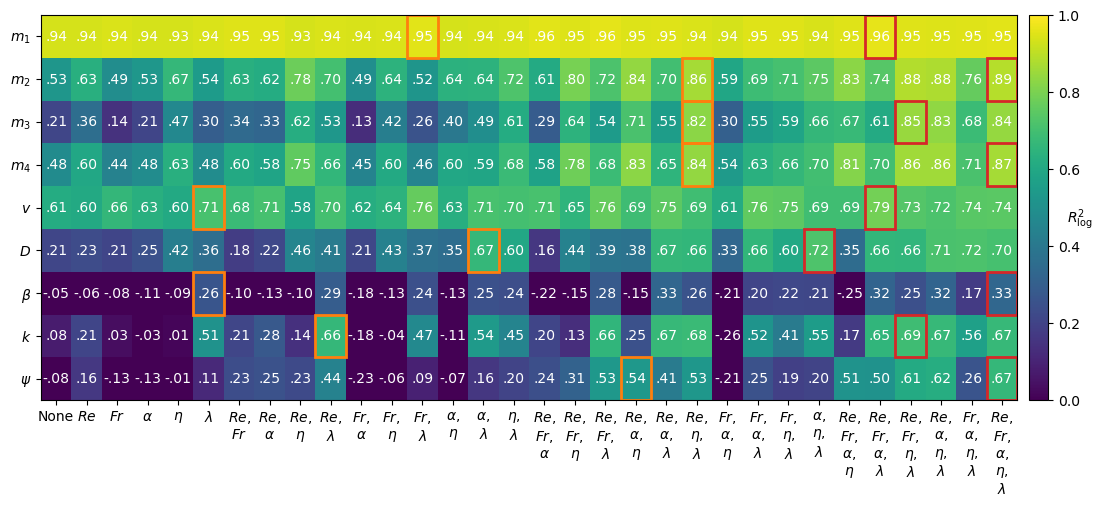

In [52]:
from matplotlib.patches import Rectangle
target_params_labels = [r'$m_1$',r'$m_2$',r'$m_3$',r'$m_4$',
                        r'$v$',r'$D$',r'$\beta$',r'$k$', '$\psi$']
fig, ax = plt.subplots(figsize=(15,5))
Z = r2_scores_multilinear[:,:,2]
pc = ax.pcolormesh([',\n'.join(i) for i in params_combinations_label],target_params_labels,Z, vmin = 0, vmax = 1)
ax.yaxis.set_inverted(True)
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        ax.text(j , i , f"{Z[i, j]:.2f}".replace("-0.", "-.").lstrip("0"),
                ha='center', va='center', color='white')
cbar = plt.colorbar(pc, pad = 0.01)
cbar.set_label(r'$R^2_{\log}$', rotation=0, labelpad=0)
for i in range(len(target_params)):
    j = np.argmax(Z[i])
    print(r'& '+target_params[i]+fr'={np.exp(all_intercepts_multilinear[i,j]):.3e}'+' '.join([fr'\cdot {m}^{{{l:.3f}}}'
                                for l,m in zip(all_coefficients_multilinear[i,j][all_coefficients_multilinear[i,j]!=0],params_combinations[j])])
          +fr' &  = {Z[i,j]:.3f} \\')
    ax.add_patch(
            Rectangle(
                (j-0.5, i-0.5), 1, 1,
                fill=False,
                edgecolor='tab:red',
                linewidth=2
            )
        )

extra_error = 1.4

for i in range(len(target_params)):
    j = np.argmax(Z[i])
    min_complex = np.array([len(k) for k in params_combinations])[(1-Z[i])/(1-Z[i,j])<extra_error][0]
    Z_i2 = Z[i].copy()
    Z_i2[np.array([len(k) for k in params_combinations])!=min_complex] = -np.inf
    j2 = np.argmax(Z_i2)
    print(r'& '+target_params[i]+fr'={np.exp(all_intercepts_multilinear[i,j2]):.3e}'+' '.join([fr'\cdot {m}^{{{l:.3f}}}'
                                for l,m in zip(all_coefficients_multilinear[i,j2][all_coefficients_multilinear[i,j2]!=0],params_combinations[j2])])
          +fr' &  = {Z[i,j2]:.3f} \\')
    ax.add_patch(Rectangle(
                (j2-0.5, i-0.5), 1, 1,
                fill=False,
                edgecolor='tab:orange',
                linewidth=2))

for i in range(len(target_params)):
    j3 = 0
    print(r'& '+target_params[i]+fr'={np.exp(all_intercepts_multilinear[i,j3]):.3e}'+' '.join([fr'\cdot {m}^{{{l:.3f}}}'
                                for l,m in zip(all_coefficients_multilinear[i,j3][all_coefficients_multilinear[i,j3]!=0],params_combinations[j3])])
          +fr' &  = {Z[i,j3]:.3f} \\')

In [93]:
np.max(r2_scores_multilinear[:,:,0],axis = 1)[:4],np.max(r2_scores_multilinear[:,:,1],axis = 1)[:4],np.max(r2_scores_multilinear[:,:,2],axis = 1)[:4]

(array([0.96781373, 0.90447109, 0.87514943, 0.89167736]),
 array([0.96097015, 0.8903253 , 0.84905469, 0.86828958]),
 array([0.96100634, 0.88906104, 0.8458967 , 0.86675494]))

In [38]:
for hyd_par_dimless in hydraulic_params_cols_reach_mean_dimless+['dim_m2_2D_ratio','psi','Deng_D_ratio']:
    print(' & '+format(np.exp(np.mean(np.log(df_filt[hyd_par_dimless]))),f'.{max(0,int(-np.log10(np.exp(np.mean(np.log(df_filt[hyd_par_dimless]))))+4))}f')+
          ' & '+' & '.join([format(i,f'.{max(0,int(-np.log10(i)+4))}f') for i in np.percentile(df_filt[hyd_par_dimless].values,[5,25,50,75,95])])+r'\\')
print(' & '+format(np.exp(np.mean(np.log(70/(df_filt['Re']*df_filt['alpha'])))),f'.{max(0,int(-np.log10(np.exp(np.mean(np.log(  70/(df_filt["Re"]*df_filt["alpha"])  ))))+4))}f')+
          ' & '+' & '.join([format(i,f'.{max(0,int(-np.log10(i)+4))}f') for i in np.percentile(70/(df_filt['Re']*df_filt['alpha']),[5,25,50,75,95])])+r'\\')

 & 365716 & 80456 & 102528 & 252064 & 908972 & 5668179\\
 & 0.1325 & 0.04620 & 0.09850 & 0.1485 & 0.1921 & 0.2948\\
 & 0.1722 & 0.07131 & 0.1180 & 0.1558 & 0.2381 & 0.5703\\
 & 41.90 & 15.12 & 25.00 & 43.20 & 68.21 & 115.5\\
 & 555.0 & 38.51 & 242.3 & 665.7 & 1657 & 4857\\
 & 11.35 & 1.034 & 3.985 & 9.686 & 36.67 & 172.0\\
 & 10.47 & 0.9580 & 3.062 & 9.690 & 27.87 & 168.8\\
 & 1.084 & 0.1611 & 0.3919 & 0.7671 & 2.872 & 17.15\\
 & 0.001112 & 0.0001313 & 0.0005084 & 0.001301 & 0.002438 & 0.005592\\


In [39]:
target_params

['m1_dimless',
 'm2_dimless',
 'm3_dimless',
 'm4_dimless',
 'v_dimless',
 'D_dimless',
 'beta_dimless',
 'k_dimless',
 'psi_dimless']

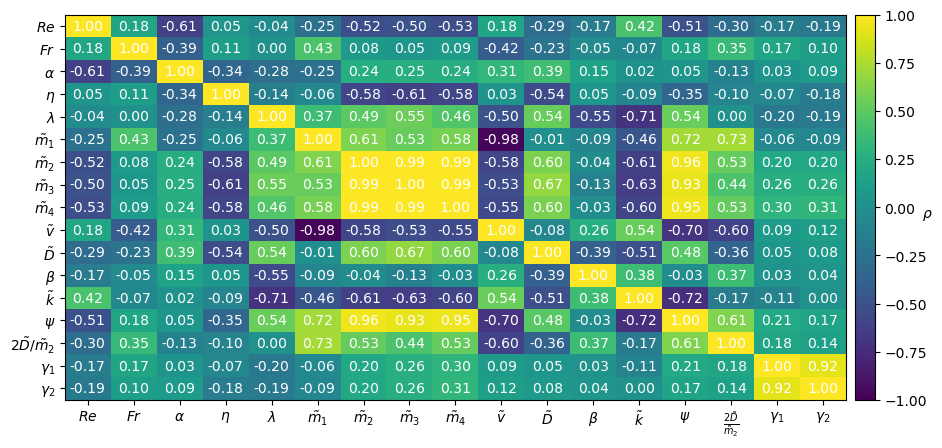

In [40]:
all_labels_0 = params_combinations_label[-1]+[fr'$\tilde{{m}}_{i}$' for i in range(1,5)]+[r'$\tilde{v}$',r'$\tilde{D}$',r'$\beta$',r'$\tilde{k}$',r'$\psi$']
all_labels_1 = all_labels_0+[r'$\frac{2\tilde{D}}{\tilde{m}_2}$',r'$\gamma_1$',r'$\gamma_2$']
all_labels_2 = all_labels_0+[r'$2\tilde{D}/\tilde{m}_2$',r'$\gamma_1$',r'$\gamma_2$']
fig, ax = plt.subplots(figsize=(12,5))
Z = np.log(df_filt[hydraulic_params_cols_reach_mean_dimless+target_params+['dim_m2_2D_ratio','skw','kurt']]).corr(numeric_only=True).values
pc = ax.pcolormesh(all_labels_1,all_labels_2,Z, vmin = -1, vmax = 1)
ax.yaxis.set_inverted(True)
cbar = plt.colorbar(pc, pad = 0.01)
cbar.set_label(r'$\rho$', rotation=0, labelpad=0)
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        ax.text(j , i , f"{Z[i, j]:.2f}",
                ha='center', va='center', color='white')

In [41]:
r2_score(np.log(df_filt['D']),np.log(df_filt['Deng_D_ratio'])+np.log(df_filt['D']))

0.4828232936459148

In [42]:
lambda_exp_D = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['D']), 1)[0]
lambda_exp_m2 = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['m2']), 1)[0]
lambda_exp_beta = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['beta']), 1)[0]
lambda_exp_k = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['k']), 1)[0]
lambda_exp_skw = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['skw']), 1)[0]
print(lambda_exp_D,lambda_exp_m2,lambda_exp_beta,lambda_exp_k)
print(lambda_exp_beta-lambda_exp_k)
print(lambda_exp_skw)
print(-(lambda_exp_beta+lambda_exp_k)/2-1/2)

0.5875484177620716 1.541950751256143 -0.2894681093987497 -0.8576605208745023
0.5681924114757526
-0.06514450820540568
0.07356431513662598


-0.06514450820540568


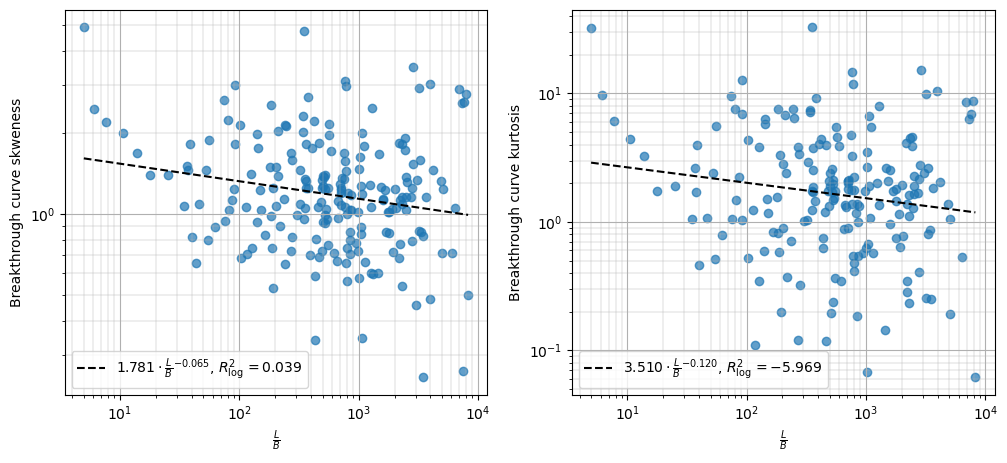

In [43]:
fig, axes = plt.subplots(figsize=(12,5), ncols = 2)
coeffs_skw = np.polyfit(np.log(df_filt['lambda']),np.log(df_filt['skw']),1)
axes[0].scatter(df_filt['lambda'],df_filt['skw'], alpha = 0.7)
axes[0].plot(np.linspace(np.min(df_filt['lambda']),np.max(df_filt['lambda'])),
             np.exp(coeffs_skw[1])*np.linspace(np.min(df_filt['lambda']),np.max(df_filt['lambda']))**coeffs_skw[0], c = 'k', linestyle = 'dashed',
            label = fr'${np.exp(coeffs_skw[1]):.3f}\cdot\frac{{L}}{{B}}^{{{coeffs_skw[0]:.3f}}}$, $R^2_{{\log}}={r2_score(np.log(df_filt["skw"]),coeffs_skw[1]+np.log(df_filt["lambda"])*coeffs_skw[0]):.3f}$')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].legend()
axes[0].grid()
axes[0].grid(which= 'minor',linewidth = 0.3)
axes[0].set_xlabel(r'$\frac{L}{B}$')
axes[0].set_ylabel(r'Breakthrough curve skweness')
axes[1].scatter(df_filt['lambda'],df_filt['exc_kurt'], alpha = 0.7)
coeffs_kurt = np.polyfit(np.log(df_filt['lambda'][df_filt['exc_kurt']>0]),np.log(df_filt['exc_kurt'][df_filt['exc_kurt']>0]),1)
axes[1].plot(np.linspace(np.min(df_filt['lambda']),np.max(df_filt['lambda'])),
             np.exp(coeffs_kurt[1])*np.linspace(np.min(df_filt['lambda']),np.max(df_filt['lambda']))**coeffs_kurt[0], c = 'k', linestyle = 'dashed',
            label = fr'${np.exp(coeffs_kurt[1]):.3f}\cdot\frac{{L}}{{B}}^{{{coeffs_kurt[0]:.3f}}}$, $R^2_{{\log}}={r2_score(np.log(df_filt["kurt"]),coeffs_kurt[1]+np.log(df_filt["lambda"])*coeffs_kurt[0]):.3f}$')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].legend()
axes[1].grid()
axes[1].set_ylabel(r'Breakthrough curve kurtosis')
axes[1].grid(which= 'minor',linewidth = 0.3)
axes[1].set_xlabel(r'$\frac{L}{B}$')
print(coeffs_skw[0])

In [53]:
%%time
from sklearn.ensemble import HistGradientBoostingRegressor
r2_scores_HGBR = np.zeros((len(target_params),3))
all_preds_HGBR = np.zeros((len(target_params),3,N))
for i,target_param in enumerate(target_params):
    y = df_filt[target_param].values
    y_log = np.log(y)
    dim_ratio = (df_filt[target_param.replace('_dimless', "")].values/
                        df_filt[target_param].values)
    part_params = params_combinations[-1]
    hydr_meas_dimless = df_filt[part_params].values
    hydr_meas_dimless_log = np.log(hydr_meas_dimless)
    for k,groups in enumerate([groups_btc,groups_trac,groups_river]):
        y_log_pred = np.zeros_like(y_log)
        for group in groups:
            model = HistGradientBoostingRegressor(max_iter=200,learning_rate=0.05,max_leaf_nodes=7,min_samples_leaf=10,l2_regularization=1.0,random_state=42)
            mask_group = np.isin(np.arange(N),group)
            model.fit(hydr_meas_dimless_log[~mask_group], y_log[~mask_group])
            y_log_pred[mask_group] = model.predict(hydr_meas_dimless_log[mask_group])
        r2 = r2_score(y_log+np.log(dim_ratio), y_log_pred+np.log(dim_ratio))
        all_preds_HGBR[i][k] = np.exp(y_log_pred+np.log(dim_ratio))
        r2_scores_HGBR[i][k] = r2
    lin_model = LinearRegression()
    lin_model.fit(hydr_meas_dimless_log, y_log)
    y_log_pred = lin_model.predict(hydr_meas_dimless_log)
    intercept = lin_model.intercept_
    coefficients = lin_model.coef_

CPU times: total: 42min 7s
Wall time: 6min 6s


In [54]:
def moms_fo_mfe(params):
    x = params[...,0]
    v = params[...,1]
    D = params[...,2]
    beta = params[...,3]
    kr = params[...,4]

    m2_0 = 0
    
    m1 = (1 + beta) * x / v

    m2 = ( (
            2 * (1 + beta)**2 * D / v**2
            + 2 * beta / kr
        )
        * x / v
    )

    m3 = (
        (
            6 * beta / kr**2
            + 12 * (1 + beta) * beta * D / (kr * v**2)
            + 12 * (1 + beta)**3 * D**2 / v**4
        )
        * x / v
    )

    m4 = ((24 * beta / kr**3
            + 12 * beta / kr * m2_0
            + 24 * beta**2 * D / (kr**2 * v**2)
            + 48 * (1 + beta) * beta * D / (kr * v**2)
            + 12 * (1 + beta)**2 * D / v**2 * m2_0
            + 144 * beta * (1 + beta)**2 * D**2 / (kr * v**4)
            + 120 * (1 + beta)**4 * D**3 / v**6
        )* x / v+
        (24 * beta * (1 + beta)**2 * D / (kr * v**2)
            + 12 * beta**2 / kr**2
            + 12 * (1 + beta)**4 * D**2 / v**4
        )* (x / v)**2
    )
    return m1, m2, m3, m4

In [55]:
moms_transp_mod_est_multilinear = np.zeros((4,3,N))
moms_transp_mod_r2_multilinear = np.zeros((4,3))
for i in range(3):
    model_est_params = np.concatenate((df_filt['L'].values[None,:],all_preds_multilinear[4:-1,-1,i,:]),axis=0).T
    moms_est = moms_fo_mfe(model_est_params)
    for j,mom in enumerate(['m1','m2','m3','m4']):
        moms_transp_mod_est_multilinear[j,i] = moms_est[j]
        moms_transp_mod_r2_multilinear[j,i] = r2_score(np.log(moms_est[j]),np.log(df_filt[mom]))

In [56]:
moms_transp_mod_est_HGBR = np.zeros((4,3,N))
moms_transp_mod_r2_HGBR = np.zeros((4,3))
for i in range(3):
    model_est_params = np.concatenate((df_filt['L'].values[None,:],all_preds_HGBR[4:-1,i,:]),axis=0).T
    moms_est = moms_fo_mfe(model_est_params)
    for j,mom in enumerate(['m1','m2','m3','m4']):
        moms_transp_mod_est_HGBR[j,i] = moms_est[j]
        moms_transp_mod_r2_HGBR[j,i] = r2_score(np.log(moms_est[j]),np.log(df_filt[mom]))

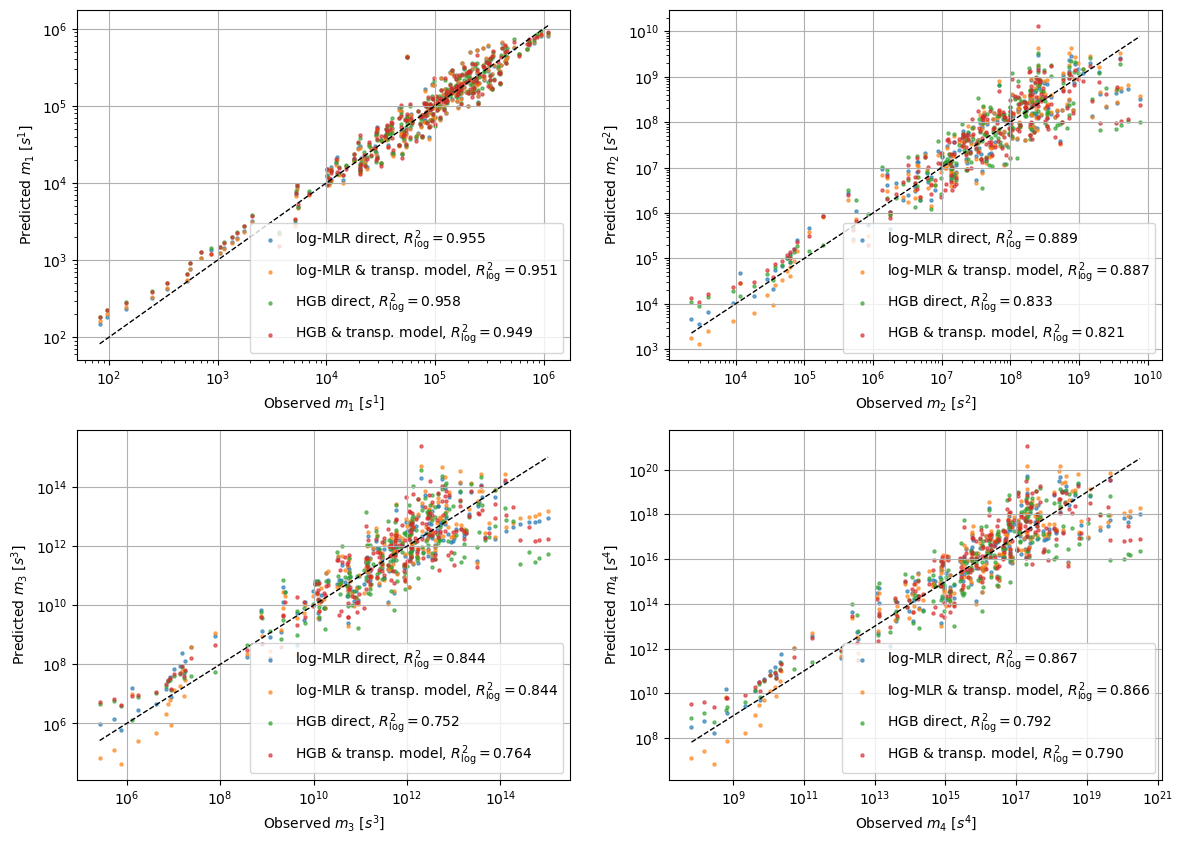

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, ax in enumerate(axes):
    ax.scatter(df_filt[['m1','m2','m3','m4'][i]],all_preds_multilinear[i,-1,-1], s = 5,alpha=0.6, label = r'log-MLR direct, $R^2_{\text{\log}}=$'
               +format(r2_scores_multilinear[i,-1,-1],'.3f'))

    ax.scatter(df_filt[['m1','m2','m3','m4'][i]],moms_transp_mod_est_multilinear[i,-1], s = 5,alpha=0.6, label = r'log-MLR & transp. model, $R^2_{\text{\log}}=$'
               +format(moms_transp_mod_r2_multilinear[i,-1],'.3f'))
    
    ax.scatter(df_filt[['m1','m2','m3','m4'][i]],all_preds_HGBR[i,-1], s = 5,alpha=0.6, label = r'HGB direct, $R^2_{\text{\log}}=$'
               +format(r2_scores_HGBR[i,-1],'.3f'))

    ax.scatter(df_filt[['m1','m2','m3','m4'][i]],moms_transp_mod_est_HGBR[i,-1], s = 5,alpha=0.6, label = r'HGB & transp. model, $R^2_{\text{\log}}=$'
               +format(moms_transp_mod_r2_HGBR[i,-1],'.3f'))
   
    ax.plot([df_filt[['m1','m2','m3','m4'][i]].min(),df_filt[['m1','m2','m3','m4'][i]].max()],
            [df_filt[['m1','m2','m3','m4'][i]].min(), df_filt[['m1','m2','m3','m4'][i]].max()],
            c='k',linestyle="--", linewidth=1)
    # fig.colorbar(sc)
    ax.set_xlabel(fr"Observed $m_{i+1}$ [$s^{i+1}$]")
    ax.set_ylabel(fr"Predicted $m_{i+1}$ [$s^{i+1}$]")
    # ax.set_title(model_params_cols[i])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.grid()
    ax.legend()

In [58]:
for ii,i in enumerate(r2_scores_multilinear[:4,-1].T):
    print(['BTC','Tracer','River'][ii],[format(j,'.3f') for j in i])

BTC ['0.968', '0.904', '0.875', '0.892']
Tracer ['0.956', '0.890', '0.845', '0.868']
River ['0.955', '0.889', '0.844', '0.867']


In [104]:
print('HGBR  regression performance compared to log-MLR')
for ii,i in enumerate(((1-r2_scores_HGBR[:4])/(1-np.max(r2_scores_multilinear[:4],axis = 1))-1).T):
    print(['BTC','Tracer','River'][ii],[format(j,'.1%') for j in i])

HGBR  regression performance compared to log-MLR
BTC ['-47.6%', '-31.5%', '-24.2%', '-30.2%']
Tracer ['11.7%', '45.6%', '63.2%', '52.0%']
River ['8.0%', '50.5%', '60.8%', '56.0%']


NameError: name 'models' is not defined

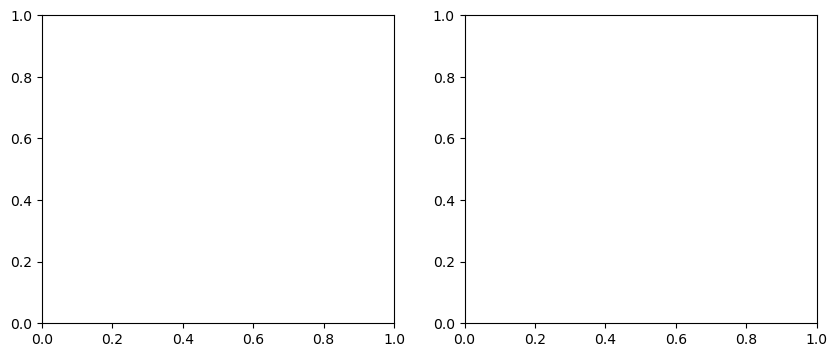

In [60]:
from matplotlib.colors import TABLEAU_COLORS

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)


for ax, k in zip(axes, [0,1]):
    model = models[k]
    for j,approach in enumerate(['Direct', 'First-order MFE']):

        for i,moment in enumerate(['m1', 'm2', 'm3', 'm4']):

            aux = [[r2_scores_multilinear[i,-1],r2_scores_HGBR[i]],
                  [moms_transp_mod_r2_multilinear[i],moms_transp_mod_r2_HGBR[i]]]
            ax.plot(splits,1-aux[j][k],marker=['o','^'][j], linestyle = ['solid','dashed'][j], c = list(TABLEAU_COLORS)[i])

    
    
    ax.set_title(model)
    ax.set_xlabel('Validation level',labelpad = 10.0)
    ax.set_ylim(0.0, 0.4)
    ax.grid()
    ax.grid(which = 'minor', linewidth = 0.4)
    ax.set_ylabel(r'$1-R^2_{\text{\log}}$')
 
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color='tab:blue', lw=2, label=r'$m_1$ rel. error'),
    Line2D([0], [0], color='tab:orange', lw=2, label=r'$m_2$ rel. error'),
    Line2D([0], [0], color='tab:green', lw=2, label=r'$m_3$ rel. error'),
    Line2D([0], [0], color='tab:red', lw=2, label=r'$m_4$ rel. error'),
    Line2D([0], [0], color='gray', lw=2, linestyle='solid',
           label='Pure data-driven'),
    Line2D([0], [0], color='gray', lw=2, linestyle='dashed',
           label='ADE-MFE-FO model informed'),
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=7,
    bbox_to_anchor=(0.5, -0.09),
    frameon=False
)


plt.tight_layout()
plt.show()

# Reconstruction of breakthrough curves

In [61]:
def piecewise_linear_moment(x, f, n=0):
    x = np.asarray(x, dtype=float)
    f = np.asarray(f, dtype=float)

    if len(x) != len(f):
        raise ValueError("x and f must have the same length.")

    if len(x) < 2:
        raise ValueError("x and f must contain at least 2 points.")

    if n < 0 or int(n) != n:
        raise ValueError("n must be a non-negative integer.")

    if np.any(np.diff(x) <= 0):
        raise ValueError("x must be strictly increasing.")

    n = int(n)
    total = 0.0

    for i in range(len(x) - 1):
        x0 = x[i]
        x1 = x[i + 1]
        f0 = f[i]
        f1 = f[i + 1]

        dx = x1 - x0
        df = f1 - f0

        # Integral of f(x) * x^n over [x0, x1] using local parameterization:
        # x(t) = x0 + t * dx,  f(x(t)) = f0 + t * df,  t in [0, 1]
        #
        # Integral = dx * sum_{k=0}^n binom(n, k) * x0^(n-k) * dx^k * [ f0/(k+1) + df/(k+2) ]
        
        interval_integral = 0.0
        # Compute binom(n, k) dynamically for accuracy
        binom = 1.0
        dx_k = 1.0  # dx^k

        for k in range(n + 1):
            term_f = f0 / (k + 1) + df / (k + 2)
            interval_integral += binom * (x0 ** (n - k)) * dx_k * term_f
            
            # Update binomial coefficient and dx^k for next step
            binom = binom * (n - k) / (k + 1)
            dx_k *= dx

        total += dx * interval_integral

    return total

(-3.0, 7.0)

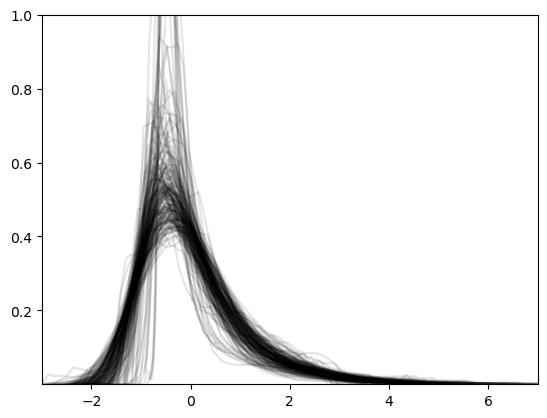

In [62]:
integration_limit=[-3,7]
z = np.linspace(integration_limit[0],integration_limit[1],(integration_limit[1]-integration_limit[0])*150)
all_btcs = np.zeros((len(df_filt.index),len(z)))
btcs_m_filt = []
ts_m_filt = []
for i,name in enumerate(df_filt.index):
    i_btc = list(names_list).index(name)
    m0 = piecewise_linear_moment(ts_m[i_btc], btcs_m[i_btc], n=0)
    m1 = piecewise_linear_moment(ts_m[i_btc], btcs_m[i_btc], n=1)/m0
    m2 = piecewise_linear_moment(ts_m[i_btc]-m1, btcs_m[i_btc], n=2)/m0
    plt.plot((ts_m[i_btc]-m1)/m2**(1/2),btcs_m[i_btc]/m0*m2**(1/2), c = 'k',alpha = 0.1)
    all_btcs[i] = np.interp(z,(ts_m[i_btc]-m1)/m2**(1/2),btcs_m[i_btc]/m0*m2**(1/2), left = 0, right = 0)
    btcs_m_filt.append(btcs_m[i_btc])
    ts_m_filt.append(ts_m[i_btc])
plt.ylim(0.00001,1)
plt.xlim(integration_limit[0],integration_limit[1])

In [63]:
m2s_filt = df_filt['m2'].values
m3s_filt = df_filt['m3'].values
m4s_filt = df_filt['m4'].values
csk_filt = m3s_filt/m2s_filt**(3/2)
kurt_filt = m4s_filt/m2s_filt**2

In [64]:
import numpy as np
from scipy.linalg import null_space
from scipy.spatial.distance import cdist


class ConstrainedZRBF:

    def __init__(self,t,f,fhat,c,n_centers=20,length_scale=None, ridge=1e-8):

        self.t = np.asarray(t)
        self.f = np.asarray(f)
        self.fhat = np.asarray(fhat)
        self.c = c

        self.Nt, self.p = self.f.shape
        self.ridge = ridge
        self.n_centers = n_centers

        # ------------------------------------------------------
        # Trapezoidal weights
        # ------------------------------------------------------

        self.w = self._trap_weights(self.t)

        # ------------------------------------------------------
        # Moment integrals of fhat
        # ------------------------------------------------------

        tc = self.t - c

        self.fhat_m2 = np.sum(
            self.w * tc**2 * self.fhat
        )

        self.fhat_m3 = np.sum(
            self.w * tc**3 * self.fhat
        )

        self.fhat_m4 = np.sum(
            self.w * tc**4 * self.fhat
        )

        # ------------------------------------------------------
        # Moment integrals of each basis function
        # ------------------------------------------------------

        self.A2 = np.sum(
            self.w[:, None]
            * tc[:, None]**2
            * self.f,
            axis=0
        )

        self.A3 = np.sum(
            self.w[:, None]
            * tc[:, None]**3
            * self.f,
            axis=0
        )

        self.A4 = np.sum(self.w[:, None]  * tc[:, None]**4 * self.f, axis=0)

        self.A = np.vstack([
            self.A2,
            self.A3,
            self.A4
        ])

        # ------------------------------------------------------
        # Null space
        # ------------------------------------------------------

        self.N = null_space(self.A)

        # Pseudoinverse for particular solution
        self.A_pinv = np.linalg.pinv(self.A)

        self.centers = None
        self.length_scale = length_scale
        self.W = None

    @staticmethod
    def _trap_weights(t):

        w = np.zeros(len(t))

        w[0] = (t[1] - t[0]) / 2
        w[-1] = (t[-1] - t[-2]) / 2

        w[1:-1] = (t[2:] - t[:-2]) / 2

        return w

    # ----------------------------------------------------------
    # Particular solution satisfying moments exactly
    # ----------------------------------------------------------

    def Z0(self, x1, x2):

        b = np.array([
            1.0 - self.fhat_m2,
            x1 - self.fhat_m3,
            x2 - self.fhat_m4
        ])

        return self.A_pinv @ b

    # ----------------------------------------------------------
    # RBF
    # ----------------------------------------------------------

    def rbf(self, X):

        d2 = cdist(
            X,
            self.centers,
            metric="sqeuclidean"
        )

        return np.exp(
            -0.5 * d2 / self.length_scale**2
        )

    # ----------------------------------------------------------
    # Fit
    # ----------------------------------------------------------

    def fit(self, x1, x2, Z):

        X = np.column_stack([
            x1,
            x2
        ])

        # ------------------------------------------------------
        # Convert Z to null-space coefficients
        #
        # Z = Z0(x1,x2) + N alpha
        # ------------------------------------------------------

        alpha = np.zeros(
            (len(X), self.N.shape[1])
        )

        for j in range(len(X)):

            z0 = self.Z0(
                x1[j],
                x2[j]
            )

            alpha[j] = np.linalg.lstsq(
                self.N,
                Z[j] - z0,
                rcond=None
            )[0]

        self.X_train = X
        self.alpha_train = alpha

        # ------------------------------------------------------
        # Select RBF centers
        # ------------------------------------------------------

        if self.n_centers >= len(X):

            self.centers = X.copy()

        else:

            # Farthest-point-ish simple selection
            # via evenly spaced points after sorting x1

            idx = np.linspace(
                0,
                len(X) - 1,
                self.n_centers
            ).astype(int)

            order = np.argsort(X[:, 0])

            self.centers = X[order[idx]]

        # ------------------------------------------------------
        # Length scale
        # ------------------------------------------------------

        if self.length_scale is None:

            d = cdist(
                self.centers,
                self.centers
            )

            d = d[d > 0]

            self.length_scale = np.median(d)

        Phi = self.rbf(X)

        # ------------------------------------------------------
        # Ridge regression
        # ------------------------------------------------------

        lhs = Phi.T @ Phi

        lhs += self.ridge * np.eye(
            lhs.shape[0]
        )

        rhs = Phi.T @ alpha

        self.W = np.linalg.solve(
            lhs,
            rhs
        )

        return self

    # ----------------------------------------------------------
    # Predict alpha
    # ----------------------------------------------------------

    def predict_alpha(self, x1, x2):

        X = np.column_stack([
            np.atleast_1d(x1),
            np.atleast_1d(x2)
        ])

        return self.rbf(X) @ self.W

    # ----------------------------------------------------------
    # Predict Z
    # ----------------------------------------------------------

    def predict_Z(self, x1, x2):

        x1 = np.atleast_1d(x1)
        x2 = np.atleast_1d(x2)

        alpha = self.predict_alpha(
            x1,
            x2
        )

        Z = np.zeros(
            (len(x1), self.p)
        )

        for j in range(len(x1)):

            Z[j] = (
                self.Z0(x1[j], x2[j])
                +
                self.N @ alpha[j]
            )

        return Z

    # ----------------------------------------------------------
    # Predict BTC
    # ----------------------------------------------------------

    def predict_h(self, x1, x2):

        Z = self.predict_Z(
            x1,
            x2
        )

        return (
            self.fhat[None, :]
            +
            Z @ self.f.T
        )

    # ----------------------------------------------------------
    # Check moments
    # ----------------------------------------------------------

    def check_moments(self, x1, x2):

        Z = self.predict_Z(
            x1,
            x2
        )

        m2 = (
            self.fhat_m2
            +
            Z @ self.A2
        )

        m3 = (
            self.fhat_m3
            +
            Z @ self.A3
        )

        m4 = (
            self.fhat_m4
            +
            Z @ self.A4
        )

        return m2, m3, m4

In [65]:
def get_optimal_Z(t,f,fhat,h,x1,x2,c):
    t = np.asarray(t)
    f = np.asarray(f)
    fhat = np.asarray(fhat)
    h = np.asarray(h)

    Nt, p = f.shape
    n_samples = len(h)

    # ----------------------------------------------------------
    # Quadrature
    # ----------------------------------------------------------

    w = np.zeros(Nt)

    w[0] = (t[1] - t[0]) / 2
    w[-1] = (t[-1] - t[-2]) / 2
    w[1:-1] = (t[2:] - t[:-2]) / 2

    # ----------------------------------------------------------
    # Weighted least squares
    # ----------------------------------------------------------

    H = f.T @ (w[:, None] * f)

    # ----------------------------------------------------------
    # Moment matrix
    # ----------------------------------------------------------

    tc = t - c

    A2 = np.sum( w[:, None]  * tc[:, None]**2 * f,  axis=0  )

    A3 = np.sum(     w[:, None]  * tc[:, None]**3  * f, axis=0 )
    A4 = np.sum(  w[:, None]  * tc[:, None]**4  * f,   axis=0  )

    A = np.vstack([  A2,   A3,    A4 ])

    # ----------------------------------------------------------
    # Moments of fhat
    # ----------------------------------------------------------

    mh2 = np.sum(w * tc**2 * fhat)
    mh3 = np.sum(w * tc**3 * fhat)
    mh4 = np.sum(w * tc**4 * fhat)

    # ----------------------------------------------------------
    # KKT matrix
    # ----------------------------------------------------------

    KKT = np.block([
        [      H,      A.T    ],
        [      A, np.zeros((3, 3))]
    ])

    Z = np.zeros((n_samples, p))

    # ----------------------------------------------------------
    # Solve each BTC
    # ----------------------------------------------------------

    for j in range(n_samples):

        q = f.T @ (      w * (h[j] - fhat)      )

        b = np.array([   1.0 - mh2,    x1[j] - mh3,    x2[j] - mh4    ])

        rhs = np.concatenate([     q,     b    ])

        sol = np.linalg.solve(        KKT,         rhs     )

        Z[j] = sol[:p]

    return Z

In [66]:
from scipy.optimize import minimize_scalar

def align_btc_rmsd(t,btc1,t2,btc2,n_scale=51,scale_factor=1.0,n_shift=51):

    t = np.asarray(t)
    btc1 = np.asarray(btc1)
    t2 = np.asarray(t2)
    btc2 = np.asarray(btc2)

    # ------------------------------------------------------------
    # Basic checks
    # ------------------------------------------------------------
    if len(t) != len(btc1):
        raise ValueError("t and btc1 must have the same length.")

    if len(t2) != len(btc2):
        raise ValueError("t2 and btc2 must have the same length.")

    # Sort both curves by time
    i1 = np.argsort(t)
    t = t[i1]
    btc1 = btc1[i1]

    i2 = np.argsort(t2)
    t2 = t2[i2]
    btc2 = btc2[i2]

    # ------------------------------------------------------------
    # Helper: moments of a BTC
    # ------------------------------------------------------------
    def btc_moments(ti, yi):
        """
        Zeroth moment, mean time, and second central moment.
        Uses trapezoidal integration.
        """
        m0 = np.trapezoid(yi, ti)

        if m0 <= 0:
            raise ValueError("BTC integral must be positive.")

        mean = np.trapezoid(ti * yi, ti) / m0

        m2 = np.trapezoid((ti - mean)**2 * yi, ti) / m0

        return m0, mean, m2

    # ------------------------------------------------------------
    # Estimate scaling range from second central moments
    # ------------------------------------------------------------
    _, mean1, var1 = btc_moments(t, btc1)
    _, mean2, var2 = btc_moments(t2, btc2)

    # Under t_new = a*t2 + b:
    #
    # variance_new = a^2 * variance2
    #
    # Therefore an approximate scale is
    #
    # a ~ sqrt(var1 / var2)
    #
    a0 = np.sqrt(var1 / var2)

    # Allow a range around this estimate
    a_min = a0 / scale_factor
    a_max = a0 * scale_factor

    scales = np.linspace(a_min, a_max, n_scale)

    # ------------------------------------------------------------
    # Peak times
    # ------------------------------------------------------------
    t_peak1 = t[np.argmax(btc1)]
    t_peak2 = t2[np.argmax(btc2)]

    # For a given scale, approximate shift from peak alignment
    #
    # t_peak1 ~= a*t_peak2 + b
    #
    # => b ~= t_peak1 - a*t_peak2
    #
    # We search around this value.
    # ------------------------------------------------------------

    def interpolate_transformed(a, b):
        """
        Interpolate btc2(t2) onto the common t grid after
        transformation t2_new = a*t2 + b.
        """
        t2_new = a * t2 + b

        btc2_new = np.interp(t,t2_new, btc2, left=0.0, right=0.0)

        return btc2_new

    # ------------------------------------------------------------
    # Find optimal shift for a given scale
    # ------------------------------------------------------------
    def optimize_shift(a):
        b0 = t_peak1 - a * t_peak2

        limit = 0.8
        i1_1,i2_1 = np.where(btc1>limit*np.max(btc1))[0][[0,-1]]
        i1_2,i2_2 = np.where(btc2>limit*np.max(btc2))[0][[0,-1]]

        b_lo = min(t[i1_1]-a * t2[i2_2],t[i2_1]-a * t2[i1_2])
        b_hi = max(t[i1_1]-a * t2[i2_2],t[i2_1]-a * t2[i1_2])

        def objective(b):
            btc2_i = interpolate_transformed(a, b)

            # Penalize cases with essentially no overlap
            if np.all(btc2_i == 0):
                return np.inf

            return RMSD_func(t, btc1, btc2_i)

        result = minimize_scalar( objective, bounds=(b_lo, b_hi), method="bounded")

        return result.fun, result.x

    # ------------------------------------------------------------
    # Coarse scale search
    # ------------------------------------------------------------
    best_rmsd = np.inf
    best_a = None
    best_b = None

    for a in scales:

        rmsd, b = optimize_shift(a)

        if rmsd < best_rmsd:
            best_rmsd = rmsd
            best_a = a
            best_b = b

    # ------------------------------------------------------------
    # Refine the scale around the best value
    # ------------------------------------------------------------
    scale_step = scales[1] - scales[0]

    a_lo = max(a_min, best_a - 2 * scale_step)
    a_hi = min(a_max, best_a + 2 * scale_step)

    def objective_scale(a):
        rmsd, _ = optimize_shift(a)
        return rmsd

    result_scale = minimize_scalar(
        objective_scale,
        bounds=(a_lo, a_hi),
        method="bounded"
    )

    best_a = result_scale.x
    best_rmsd, best_b = optimize_shift(best_a)

    # Final interpolation
    btc2_interp = interpolate_transformed(best_a, best_b)

    t2_aligned = best_a * t2 + best_b

    _, c_scale = RMSD_func(t,btc1,btc2_interp, return_a = True)
    
    return { "rmsd": best_rmsd, "scale": best_a, "shift": best_b, "t2_aligned": t2_aligned,
        "btc2_interp": btc2_interp, "initial_scale": a0, "scale_range": (a_min, a_max), "c_scale": c_scale}

In [67]:
river_names_list_filt = np.array([str(i).split(' ')[0] for i in df_filt.index])
tracer_names_list_filt = np.array([' '.join(str(i).split(' ')[:2]) for i in df_filt.index])
unique_riv, btc_riv_loc = np.unique(river_names_list_filt,return_inverse = True)
unique_trac, btc_trac_loc = np.unique(tracer_names_list_filt,return_inverse = True)

In [68]:
def obtain_btc_pred_model(test_split,train_split):
        # ==============================================================
    # STEP 1
    # Build KL expansion
    # ==============================================================
    
    p = 16
    mean_btc = np.mean(all_btcs[train_split],axis = 0)
    btc_diff = all_btcs[train_split]-mean_btc
    C = btc_diff.T @ btc_diff / (btc_diff.shape[0] - 1)
    eigvals, eigvecs = np.linalg.eigh(C)
    idx = np.argsort(eigvals)[::-1]
    lambdas = eigvals[idx][:p]
    phis = eigvecs[:, idx][:,:p]
    
    # ==============================================================
    # STEP 2
    # Find the optimal Z for each of your 200 BTCs
    # ==============================================================
    
    Z_train = get_optimal_Z(
        t=z,
        f=phis,
        fhat=mean_btc,
        h=all_btcs[train_split],
        x1=csk_filt[train_split],
        x2=kurt_filt[train_split],
        c=0
    )
    
    
    # # ==============================================================
    # # STEP 3
    # # Learn Z(x1,x2)
    # # ==============================================================
    
    model = ConstrainedZRBF(
        t=z,
        f=phis,
        fhat=mean_btc,
        c=0,
        n_centers=20,
        ridge=1e-8
    )
    
    model.fit(
        x1=csk_filt[train_split],
        x2=kurt_filt[train_split],
        Z=Z_train
    )
    return model
    

In [69]:
%%time
btc_pred_models_LOO_btc = []
for i_btc in range(len(all_btcs)):
    test_split = np.array([i_btc])
    train_split = np.array([i for i in np.arange(len(all_btcs)) if i not in test_split])
    
    btc_pred_models_LOO_btc.append(obtain_btc_pred_model(test_split,train_split))


CPU times: total: 6min 22s
Wall time: 2min 1s


In [70]:
%%time
RMSEs_ogmoms_LOO_btc = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,btc_pred_models_LOO_btc[i_btc].predict_h(csk_filt[i_btc],kurt_filt[i_btc])[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_multilinear_LOO_btc = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_btc[i_btc].predict_h(all_preds_multilinear[2,-1,0,i_btc]/all_preds_multilinear[1,-1,0,i_btc]**(3/2),
                                                         all_preds_multilinear[3,-1,0,i_btc]/all_preds_multilinear[1,-1,0,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_HGB_LOO_btc = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_btc[i_btc].predict_h(all_preds_HGBR[2,0,i_btc]/all_preds_HGBR[1,0,i_btc]**(3/2),
                                                         all_preds_HGBR[3,0,i_btc]/all_preds_HGBR[1,0,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])

CPU times: total: 35 s
Wall time: 35.2 s


In [71]:
%%time
btc_pred_models_LOO_trac = []
for trac in unique_trac:
    test_split = np.where(btc_trac_loc==np.where(unique_trac==trac)[0][0])[0]
    train_split = np.array([i for i in np.arange(len(all_btcs)) if i not in test_split])
    btc_pred_models_LOO_trac.append(obtain_btc_pred_model(test_split,train_split))

CPU times: total: 1min 12s
Wall time: 22.8 s


In [72]:
%%time
RMSEs_ogmoms_LOO_trac = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,btc_pred_models_LOO_trac[btc_trac_loc[i_btc]].predict_h(csk_filt[i_btc],kurt_filt[i_btc])[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_multilinear_LOO_trac = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_trac[btc_trac_loc[i_btc]].predict_h(all_preds_multilinear[2,-1,1,i_btc]/all_preds_multilinear[1,-1,1,i_btc]**(3/2),
                                                         all_preds_multilinear[3,-1,1,i_btc]/all_preds_multilinear[1,-1,1,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_HGB_LOO_trac = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_trac[btc_trac_loc[i_btc]].predict_h(all_preds_HGBR[2,1,i_btc]/all_preds_HGBR[1,1,i_btc]**(3/2),
                                                         all_preds_HGBR[3,1,i_btc]/all_preds_HGBR[1,1,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])

CPU times: total: 35.8 s
Wall time: 36.1 s


In [73]:
%%time
btc_pred_models_LOO_riv = []
for riv in unique_riv:
    test_split = np.where(btc_riv_loc==np.where(unique_riv==riv)[0][0])[0]
    train_split = np.array([i for i in np.arange(len(all_btcs)) if i not in test_split])
    btc_pred_models_LOO_riv.append(obtain_btc_pred_model(test_split,train_split))

CPU times: total: 37.3 s
Wall time: 11.6 s


In [74]:
%%time
RMSEs_ogmoms_LOO_riv = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,btc_pred_models_LOO_riv[btc_riv_loc[i_btc]].predict_h(csk_filt[i_btc],kurt_filt[i_btc])[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_multilinear_LOO_riv = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_riv[btc_riv_loc[i_btc]].predict_h(all_preds_multilinear[2,-1,2,i_btc]/all_preds_multilinear[1,-1,2,i_btc]**(3/2),
                                                         all_preds_multilinear[3,-1,2,i_btc]/all_preds_multilinear[1,-1,2,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])
RMSEs_HGB_LOO_riv = np.array([align_btc_rmsd(z,all_btcs[i_btc],z,
                                                btc_pred_models_LOO_riv[btc_riv_loc[i_btc]].predict_h(all_preds_HGBR[2,2,i_btc]/all_preds_HGBR[1,2,i_btc]**(3/2),
                                                         all_preds_HGBR[3,2,i_btc]/all_preds_HGBR[1,2,i_btc]**(2)
                                                        )[0])['rmsd'] for i_btc in range(len(all_btcs))])

CPU times: total: 36.7 s
Wall time: 36.9 s


In [75]:
models = [
    'log-MLR',
    'HGB'
]
RMSEs_LOO_df = pd.DataFrame({
    'Original' : [np.mean(RMSEs_ogmoms_LOO_btc),np.mean(RMSEs_ogmoms_LOO_trac),np.mean(RMSEs_ogmoms_LOO_riv)],
    models[0]: [np.mean(RMSEs_multilinear_LOO_btc), np.mean(RMSEs_multilinear_LOO_trac), np.mean(RMSEs_multilinear_LOO_riv)],
    models[1]: [np.mean(RMSEs_HGB_LOO_btc), np.mean(RMSEs_HGB_LOO_trac), np.mean(RMSEs_HGB_LOO_riv)]
})
splits = ['Breakthrough curve','Tracer test','River']
RMSEs_LOO_df.index = splits


In [76]:
import numpy as np
# This is a python translation of the program written by Hollenbeck, K. J. (1998)
#
# DEHOOG - numerical inverse Laplace transform
#
# Description:
#   algorithm: de Hoog et al's quotient difference method with accelerated
#   convergence for the continued fraction expansion
#
#   [de Hoog, F. R., Knight, J. H., and Stokes, A. N. (1982). An improved
#   method for numerical inversion of Laplace transforms. S.I.A.M. J. Sci.
#   and Stat. Comput., 3, 357-366.]
#
#   Modification: The time vector is split in segments of equal magnitude
#   which are inverted individually. This gives a better overall accuracy.
#
#   Details: de Hoog et al's algorithm f4 with modifications (T->2*T and
#    introduction of tol). Corrected error in formulation of z.
#
#   Copyright: Karl Hollenbeck
#             Department of Hydrodynamics and Water Resources
#             Technical University of Denmark, DK-2800 Lyngby
#             email: karl@isv16.isva.dtu.dk
#
#   22 Nov 1996, MATLAB 5 version 27 Jun 1997 updated 1 Oct 1998
#   IF YOU PUBLISH WORK BENEFITING FROM THIS M-FILE, PLEASE CITE IT AS:
#       Hollenbeck, K. J. (1998) INVLAP.M: A matlab function for numerical
#       inversion of Laplace transforms by the de Hoog algorithm,
#       http://www.isva.dtu.dk/staff/karl/invlap.htm
#
#   Renamed by P. Renard to be integrated in the hytool toolbox.
#
# example:
#   identity function in Laplace space:
#   F = lambda s: 1/(s**2)
#   invlap(F, np.array([1,2,3]))                # gives [1,2,3]
#
# See also: stefhest
#

import numpy as np
import warnings

warnings.filterwarnings('ignore', 'overflow')
warnings.filterwarnings('ignore', 'invalid')
warnings.filterwarnings('ignore', 'divide')

def invlap(F, t,args, alpha=0, tol=1e-10,M = 200):
    """
    F      = laplace-space function (string refering to an m-file),must
             have form F(s, args), where s is the Laplace parameter
             and return column vector as result
    t      = column vector of times for which real-space function values
             are sought
    args   = other parameters of F
    alpha  = largest pole of F (default zero)
    tol    = numerical tolerance of approaching pole (default 1e-10)
    f      = vector of real-space values f(t)
    """
    f = []
    # Split up t vector in pieces of the same order of magnitude, invert one piece
    # at a time. Simultaneous inversion for times covering several orders of
    # magnitudes gives inaccurate results for the small times.
    allt = t
    logallt = np.log10(allt)
    iminlogallt = int(np.floor(np.min(logallt)))
    imaxlogallt = int(np.ceil(np.max(logallt)))

    for ilogt in range(iminlogallt, imaxlogallt + 1):
        t = allt[(logallt >= ilogt) & (logallt < (ilogt + 1))]
        if t.size > 0:  # Maybe no elements in that magnitude
            T = np.max(t) * 2
            gamma = alpha - np.log(tol) / (2 * T)
            # NOTE: The correction alpha -> alpha-log(tol)/(2*T) is not in de Hoog's
            #   paper, but in Mathematica's Mathsource (NLapInv.m) implementation of
            #   inverse transforms
            nt = len(t)
            run = np.arange(2 * M + 1)  # so there are 2M+1 terms in Fourier series expansion

            # Find F argument, call F with it, get 'a' coefficients in power series
            s = gamma + 1j * np.pi * run / T
            a = F(s, *args)
            a = a.flatten()
            a[0] = a[0] / 2  # zero term is halved

            # Build up e and q tables. Superscript is now row index, subscript column
            # CAREFUL: paper uses null index, so all indices are shifted by 1 here
            e = np.zeros((2 * M + 1, M + 1), dtype=complex)
            q = np.zeros((2 * M, M + 1), dtype=complex)  # Column 0 (here: 1) does not exist
            e[:, 0] = np.zeros(2 * M + 1)
            q[:, 1] = a[1:2 * M + 1] / a[:2 * M]
            for r in range(2, M + 2):  # Step through columns (called r...)
                e[:2 * (M - r+1), r-1] = q[1:2 * (M - r+1) + 1, r-1] - q[:2 * (M - r+1), r-1] + e[1:2 * (M - r+1) + 1, r - 2]
                if r < M:  # One column fewer for q
                    rq = r + 1
                    q[:2 * (M - rq) + 2, rq-1] = q[1:2 * (M - rq) + 3, rq - 2] * e[1:2 * (M - rq) + 3, rq - 2] / e[:2 * (M - rq) + 2, rq - 2]

            # Build up d vector (index shift: 1)
            d = np.zeros(2 * M + 1, dtype=complex)
            d[0] = a[0]
#             d[1::2] = -q[:M, 1:M + 1].diagonal()
#             d[2::2] = -e[:M, 1:M + 1].diagonal()
            d[1::2] = -q[0, 1:M + 1].T
            d[2::2] = -e[0, 1:M + 1].T

            # Build up A and B vectors (index shift: 2)co
            # - now make into matrices, one row for each time
            A = np.zeros((2 * M + 2, nt), dtype=complex)
            B = np.zeros((2 * M + 2, nt), dtype=complex)
            A[1, :] = d[0] * np.ones(nt)
            B[:2, :] = np.ones((2, nt))
            z = np.exp(1j * np.pi * t / T)  # Row vector

            dz = np.outer(d, z)

            for n in range(2, 2 * M + 2):
                A[n, :] = A[n - 1, :] + dz[n - 1, :] * A[n - 2, :]
                B[n, :] = B[n - 1, :] + dz[n - 1, :] * B[n - 2, :]


            # Double acceleration
            h2M = 0.5 * (1 + (d[2 * M - 1] - d[2 * M]) * z)
            R2Mz = -h2M * (1 - np.sqrt(1 + d[2 * M] * z / (h2M**2)))
            A[2 * M + 1, :] = A[2 * M, :] + R2Mz * A[2 * M - 1, :]
            B[2 * M + 1, :] = B[2 * M, :] + R2Mz * B[2 * M - 1, :]

            # Inversion, vectorized for times, make result a column vector
            fpiece = (1 / T * np.exp(gamma * t) * np.real(A[2 * M + 1, :] / B[2 * M + 1, :])).flatten()
            f.extend(fpiece)

    return np.array(f)

from scipy.special import expn
from mpmath import expint

def ADEMF_1D(ts, xs, v, Pe, beta, g_params, memory_func, bound_cond):
    """
    Solves the memory function advection-dispersion-immobile-exchange model with constant coefficients
    ts = Array. Times after release
    xs = Array. Distance from the point of release
    v = Float. Advection velocity
    Pe = Float. Peclet number
    beta = Float. Ratio between the effective immobile phase area and the mobile phase area
    g_params = List of the parameters of the corresponding memory function
                'first order' takes [k_f,k_r]
                'power law' takes [alpha,1-gamma]
    memory_func = Either 'first order' or 'power law', others can be added editing c_lap_space
    bound_cond = Either 'semi-infinite-conc', 'semi-infinite-mixed', or 'infinite'
                'semi-infinite-conc' is a domain x>0 with vc(x=0,t)=M_0 delta(t)
                'semi-infinite-mixed' is a domain x>0 with vc(x=0,t)- 2 D dc/dx (x=0,t) =M_0 delta(t)
                'infinite' is a domain x>0 with vc(x=0,t)-2 D dc/dx (x=0,t) =M_0 delta(t). The solution to this problem is equivalent to the solution in the infinite domain
    """
    exp_int_ = np.vectorize(lambda s: complex(expint(g_params[1]+1,s/g_params[0])))
    def sol_lap_space(s, x):
        """
        Auxilitary function for c_lap_solver
        """
        if memory_func == 'first order':
            G = lambda s,g_params: g_params[0]/(g_params[1] + s)
        if memory_func == 'power law':
            G = lambda s,g_params: g_params[0]*s**(-g_params[1])
        if memory_func == 'gamma':
            G = lambda s,g_params: g_params[1]*np.exp(s/g_params[0])*exp_int_(s)
        b = s + beta * s * G(s,g_params)
        if bound_cond == 'semi-infinite-conc':
            c = np.exp(x*(Pe- np.sqrt(Pe*(4*b+Pe)))/2)
        if bound_cond == 'semi-infinite-mixed':
            c = 1/(1/2+np.sqrt(4*b+Pe)/(2*np.sqrt(Pe)))*np.exp(x*(Pe- np.sqrt(Pe*(4*b+Pe)))/2)
        if bound_cond == 'infinite':
            c = np.sqrt(Pe/(4*b+Pe)) * np.exp((Pe*x- np.sqrt(Pe*x**2*(4*b+Pe)))/2)
        return c
    cis = np.array([invlap(sol_lap_space, ts*v/xs[-1], [x/xs[-1]]) for x in xs])*v/xs[-1]
    cis = np.nan_to_num(np.array(cis).T, 0.0)
    return cis

In [77]:
xs_filt = df_filt['L'].values
names_list_filt = df_filt['Tracer Name'].values

In [78]:
# %%time
RMSEs_dict = {}
for i,split in enumerate(splits):#row
    RMSEs_dict[split] = {}  # Initialize the nested dictionary for the current row
    for j,model in enumerate(['Original']+models):#col
        v,D,beta,kr = [df_filt[['v','D','beta','k']].values.T,all_preds_multilinear[4:-1,-1,i],all_preds_HGBR[4:-1,i]][j]
        Pe,kr_hat = v*xs_filt/D, kr*xs_filt/v
        t_est = np.linspace(0,10,150*10)[1:]
        est_btc = np.array([ADEMF_1D(t_est*xs_filt[i_btc]/v[i_btc]*(1+beta[i_btc]), [xs_filt[i_btc]], 
                    v[i_btc],Pe[i_btc],beta[i_btc],[kr_hat[i_btc],kr_hat[i_btc]], 'first order', 'infinite')[:,-1] for i_btc in range(len(all_btcs))])
            
        RMSEs_MFE = np.array([align_btc_rmsd(ts_m_filt[i_btc],btcs_m_filt[i_btc],t_est,est_btc[i_btc],n_scale=101,scale_factor=2.0,n_shift=101)['rmsd'] for i_btc in range(len(all_btcs))])
        RMSEs_dict[split][model] = np.mean(RMSEs_MFE)

RMSEs_MFE_LOO_df = pd.DataFrame.from_dict(RMSEs_dict, orient='index')
    

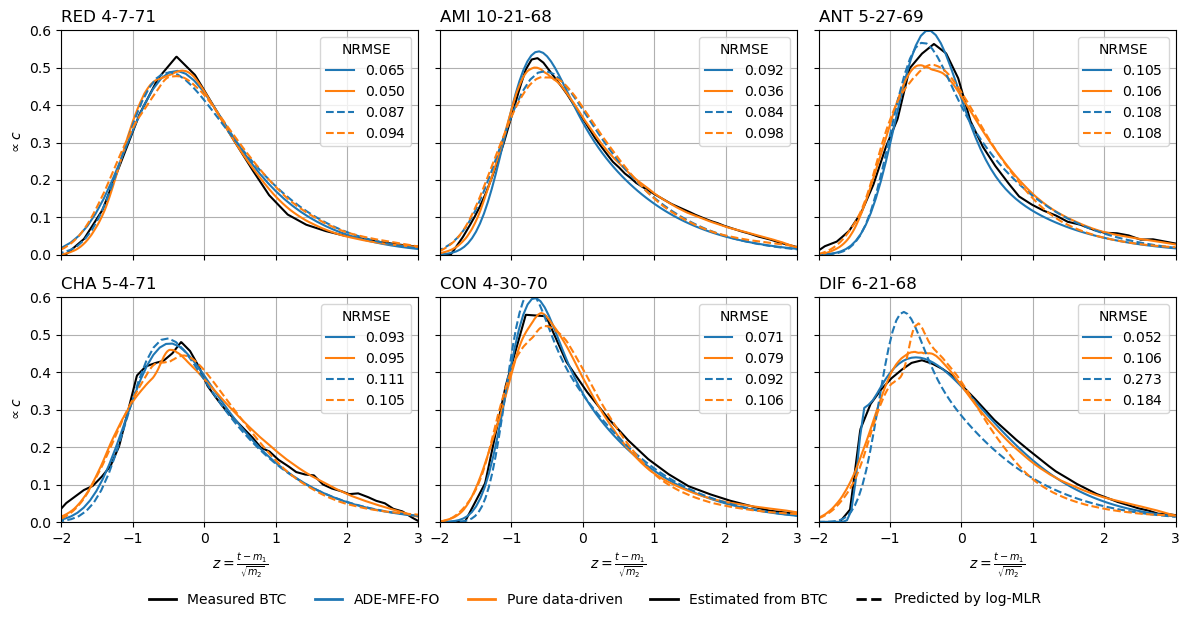

In [79]:
Nrows = 2
Ncols = 3
fig,axes = plt.subplots(nrows = Nrows, ncols = Ncols, figsize = (12,6))
np.random.seed(13)
rand_i_btcs = np.sort(np.random.choice(list(range(len(all_btcs))),size = Nrows*Ncols, replace = False))
axes = axes.flatten()
for ax,i_btc in zip(axes,rand_i_btcs):
    ax.plot(z,all_btcs[i_btc], c = 'k')
    for j,model in enumerate(['Original']+['Multilinear']):
        v,D,beta,kr = [df_filt[['v','D','beta','k']].values.T,all_preds_multilinear[4:-1,-1,-1],all_preds_HGBR[4:-1,-1]][j]
        Pe,kr_hat = v*xs_filt/D, kr*xs_filt/v
        t_est = np.linspace(0,10,150*10)[1:]
        est_btc = ADEMF_1D(t_est*xs_filt[i_btc]/v[i_btc]*(1+beta[i_btc]), [xs_filt[i_btc]], 
                    v[i_btc],Pe[i_btc],beta[i_btc],[kr_hat[i_btc],kr_hat[i_btc]], 'first order', 'infinite')[:,-1]
        al_rmsd_out = align_btc_rmsd(z,all_btcs[i_btc],t_est,est_btc)
        ax.plot(t_est*al_rmsd_out['scale']+al_rmsd_out['shift'],est_btc*al_rmsd_out['c_scale'],
                c='tab:blue',linestyle = ['solid','dashed','dotted'][j], label = fr'${al_rmsd_out["rmsd"]:.3f}$')
        csk = [df_filt['m3'].values[i_btc],all_preds_multilinear[2,-1,2,i_btc]][j]/[df_filt['m2'].values[i_btc],all_preds_multilinear[1,-1,2,i_btc]][j]**(3/2)
        kurt = [df_filt['m4'].values[i_btc],all_preds_multilinear[3,-1,2,i_btc]][j]/[df_filt['m2'].values[i_btc],all_preds_multilinear[1,-1,2,i_btc]][j]**(2)
        est_btc = btc_pred_models_LOO_riv[btc_riv_loc[i_btc]].predict_h(csk,kurt)[0]
        al_rmsd_out = align_btc_rmsd(z,all_btcs[i_btc],z,est_btc)
        ax.plot(z*al_rmsd_out['scale']+al_rmsd_out['shift'],est_btc*al_rmsd_out['c_scale'],
                c='tab:orange',linestyle = ['solid','dashed','dotted'][j], label = fr'${al_rmsd_out["rmsd"]:.3f}$')
    ax.legend(title = 'NRMSE')
    ax.set_xlim(-2,3)
    ax.set_ylim(0,0.6)
    ax.grid()
    ax.set_title(names_list_filt[i_btc], loc = 'left')

for i, ax in enumerate(axes):

    row = i // Ncols
    col = i % Ncols

    # X axis: only bottom row
    if row == Nrows - 1:
        ax.set_xlabel(r'$z = \frac{t-m_1}{\sqrt{m_2}}$')
    else:
        ax.tick_params(axis='x', labelbottom=False)

    # Y axis: only left column
    if col == 0:
        ax.set_ylabel(r'$\propto c$')
    else:
        ax.tick_params(axis='y', labelleft=False)


from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color='k', lw=2, label='Measured BTC'),
    Line2D([0], [0], color='tab:blue', lw=2, label='ADE-MFE-FO'),
    Line2D([0], [0], color='tab:orange', lw=2, label='Pure data-driven'),
    Line2D([0], [0], color='k', lw=2, linestyle='solid',
           label='Estimated from BTC'),
    Line2D([0], [0], color='k', lw=2, linestyle='dashed',
           label='Predicted by log-MLR'),
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=5,
    bbox_to_anchor=(0.5, -0.04),
    frameon=False
)
plt.tight_layout( w_pad=0.5, h_pad=1.0)

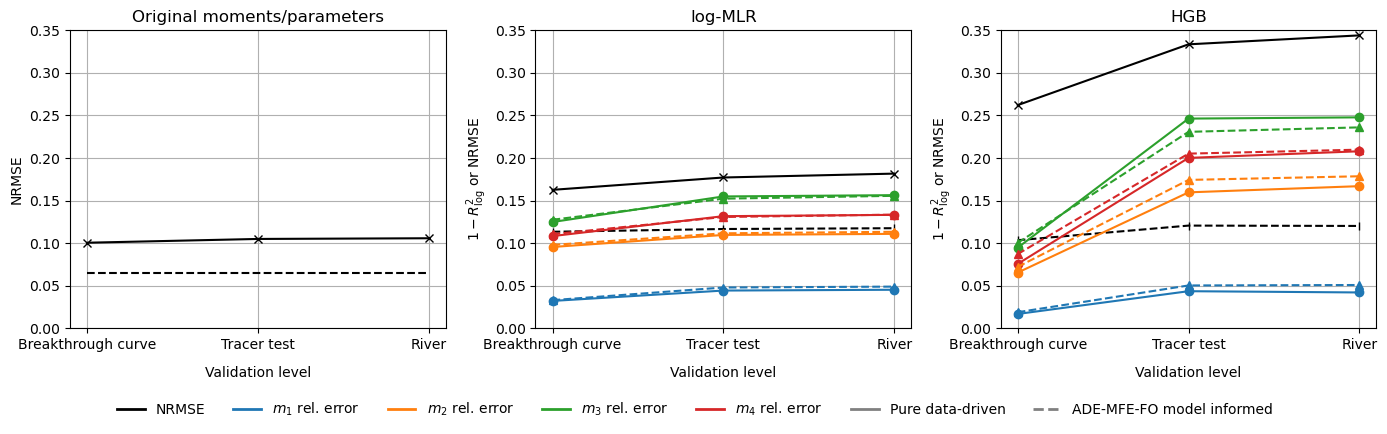

In [80]:
from matplotlib.colors import TABLEAU_COLORS

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4)
)



axes[0].plot(RMSEs_LOO_df.index,RMSEs_LOO_df['Original'],c= 'k', marker = 'x')
axes[0].plot(RMSEs_MFE_LOO_df.index,RMSEs_MFE_LOO_df['Original'],c= 'k', linestyle = 'dashed')
axes[0].set_title('Original moments/parameters')
axes[0].set_xlabel('Validation level',labelpad = 10.0)
axes[0].set_ylim(0,0.35)
axes[0].grid()
axes[0].grid(which = 'minor', linewidth = 0.4)
axes[0].set_ylabel(r'NRMSE')

for ax, k in zip(axes[1:], [0,1]):
    model = models[k]
    ax.plot(RMSEs_LOO_df.index,RMSEs_LOO_df[model],c= 'k', marker = 'x')
    ax.plot(RMSEs_MFE_LOO_df.index,RMSEs_MFE_LOO_df[model],c= 'k', linestyle = 'dashed', marker = '|')
    for j,approach in enumerate(['Direct', 'First-order MFE']):

        for i,moment in enumerate(['m1', 'm2', 'm3', 'm4']):

            aux = [[r2_scores_multilinear[i,-1],r2_scores_HGBR[i]],
                  [moms_transp_mod_r2_multilinear[i],moms_transp_mod_r2_HGBR[i]]]
            ax.plot(splits,1-aux[j][k],marker=['o','^'][j], linestyle = ['solid','dashed'][j], c = list(TABLEAU_COLORS)[i])

    
    
    ax.set_title(model)
    ax.set_xlabel('Validation level',labelpad = 10.0)
    ax.set_ylim(0.0, 0.35)
    ax.grid()
    ax.grid(which = 'minor', linewidth = 0.4)
    ax.set_ylabel(r'$1-R^2_{\text{\log}}$ or NRMSE')
 
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], color='k', lw=2, label='NRMSE'),
    Line2D([0], [0], color='tab:blue', lw=2, label=r'$m_1$ rel. error'),
    Line2D([0], [0], color='tab:orange', lw=2, label=r'$m_2$ rel. error'),
    Line2D([0], [0], color='tab:green', lw=2, label=r'$m_3$ rel. error'),
    Line2D([0], [0], color='tab:red', lw=2, label=r'$m_4$ rel. error'),
    Line2D([0], [0], color='gray', lw=2, linestyle='solid',
           label='Pure data-driven'),
    Line2D([0], [0], color='gray', lw=2, linestyle='dashed',
           label='ADE-MFE-FO model informed'),
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=7,
    bbox_to_anchor=(0.5, -0.09),
    frameon=False
)


plt.tight_layout()
plt.show()

In [81]:
RMSEs_LOO_df

,Original,log-MLR,HGB
Breakthrough curve,0.100535,0.162631,0.262114
Tracer test,0.104971,0.177125,0.333504
River,0.105774,0.181682,0.344018


In [82]:
RMSEs_MFE_LOO_df

,Original,log-MLR,HGB
Breakthrough curve,0.064678,0.113399,0.103474
Tracer test,0.064678,0.116642,0.120645
River,0.064678,0.117573,0.120226


In [83]:
RMSEs_LOO_df/RMSEs_MFE_LOO_df-1

,Original,log-MLR,HGB
Breakthrough curve,0.554384,0.434149,1.533128
Tracer test,0.622970,0.518534,1.764340
River,0.635386,0.545273,1.861418


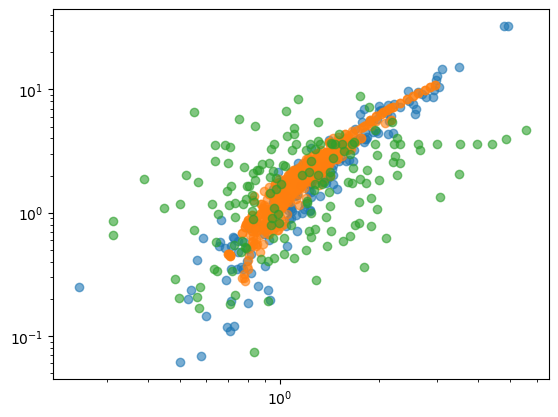

In [109]:
plt.scatter(csk_filt,kurt_filt-3, alpha = 0.6)
plt.scatter(all_preds_multilinear[2,-1]/all_preds_multilinear[1,-1]**(3/2),(all_preds_multilinear[3,-1]/all_preds_multilinear[1,-1]**(2))-3, alpha = 0.6)
plt.scatter(all_preds_HGBR[2,-1]/all_preds_HGBR[1,-1]**(3/2),(all_preds_HGBR[3,-1]/all_preds_HGBR[1,-1]**(2))-3, alpha = 0.6)
plt.xscale('log')
plt.yscale('log')